In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

import matplotlib.pyplot as plt
from IPython.display import display

/workspaces/Machine_Learning/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
loader = HFDatasetLoader(
    dataset_name="shijiabraham/insurance-data",
    split="train",
    filename="datos/insurance_data_ml_regressionlineal.csv",
)

In [3]:
df = loader.load()
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Evidencia de preprocesamiento

Se analiza la calidad de los datos del dataset Medical Insurance
para identificar valores faltantes, registros duplicados y tipos de
datos antes de entrenar los modelos.

In [4]:
# Copia de los datos originales
df_original = df.copy(deep=True)

print("Dimensiones iniciales:", df_original.shape)

print("\nTipos de datos:")
print(df_original.dtypes)

print("\nValores faltantes:")
print(df_original.isnull().sum())

print("\nRegistros duplicados:")
print(df_original.duplicated().sum())

print("\nPrimeros registros:")
display(df_original.head())

Dimensiones iniciales: (1338, 7)

Tipos de datos:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Valores faltantes:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Registros duplicados:
1

Primeros registros:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# Crear copia para realizar la limpieza
df_limpio = df_original.copy(deep=True)

# Estado inicial
filas_antes = len(df_limpio)
duplicados_antes = df_limpio.duplicated().sum()
nulos_antes = df_limpio.isnull().sum().sum()

# Eliminar duplicados exactos
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

# Estado final
filas_despues = len(df_limpio)
duplicados_despues = df_limpio.duplicated().sum()
nulos_despues = df_limpio.isnull().sum().sum()

# Comparación de resultados
comparacion = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros duplicados",
        "Valores faltantes"
    ],
    "Antes": [
        filas_antes,
        duplicados_antes,
        nulos_antes
    ],
    "Después": [
        filas_despues,
        duplicados_despues,
        nulos_despues
    ]
})

display(comparacion)

,Indicador,Antes,Después
0,Total de registros,1338,1337
1,Registros duplicados,1,0
2,Valores faltantes,0,0


### Justificación de las operaciones de preprocesamiento

Se realizó una revisión inicial para identificar valores faltantes, registros duplicados y tipos de datos del dataset Medical Insurance.

Se decidió eliminar los registros duplicados exactos para evitar la repetición de observaciones durante el entrenamiento y la evaluación de los modelos.

No fue necesario imputar valores faltantes, ya que en la revisión inicial no se identificaron datos nulos.

Las variables numéricas utilizadas para la regresión fueron `bmi`, `age` y `charges`. Además, la clase `RegresionLineal` implementa el método `preparar_datos()`, que permite seleccionar las variables, convertirlas a valores numéricos y descartar registros inválidos.

Para la clasificación se realizará posteriormente la codificación de las variables categóricas, utilizando únicamente los datos de entrenamiento para ajustar las transformaciones necesarias.

## Regresion lineal simple

### Importar la clase

In [ ]:
from clases_po import RegresionLineal

### Inicializar el modelo

In [ ]:
regresion_simple = RegresionLineal(
    feature_column="bmi",
    target_column="charges",
    test_size=0.2,
    random_state=42
)

resultado_simple = regresion_simple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['bmi'], y='charges'; 1338 filas válidas; 0 filas eliminadas; X=(1338, 1), y=(1338,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1070 filas (1070, 1); prueba=268 filas (268, 1).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 1070 filas y 1 características.
[entrenar] modelo guardado en: entrenamiento/20261023_031839_149527_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261023_031839_149527_modelo.pkl; 268 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261023_031839_149527_modelo.pkl; w=392.43654416987977; b=1353.0731.
[ejecutar][6/6] Iniciando evaluar.
[predecir] modelo cargado desde entrenamiento/20261023

### Preparar los datos

### Dividir los datos

In [ ]:
print("Variables originales:", X_clas_train.shape[1])

X_transformado = modelo_clasificacion.named_steps[
    "preprocesamiento"
].transform(X_clas_train)

print("Variables después de codificación:", X_transformado.shape[1])

print("\nColumnas resultantes:")
print(
    modelo_clasificacion.named_steps[
        "preprocesamiento"
    ].get_feature_names_out()
)

Variables originales: 5
Variables después de codificación: 9

Columnas resultantes:
['numericas__age' 'numericas__bmi' 'numericas__children'
 'categoricas__sex_female' 'categoricas__sex_male'
 'categoricas__region_northeast' 'categoricas__region_northwest'
 'categoricas__region_southeast' 'categoricas__region_southwest']


### Evaluación del modelo de clasificación

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calcular métricas
accuracy = accuracy_score(y_clas_test, predicciones_clasificacion)

precision = precision_score(
    y_clas_test,
    predicciones_clasificacion,
    pos_label="yes",
    zero_division=0
)

recall = recall_score(
    y_clas_test,
    predicciones_clasificacion,
    pos_label="yes",
    zero_division=0
)

f1 = f1_score(
    y_clas_test,
    predicciones_clasificacion,
    pos_label="yes",
    zero_division=0
)

# Mostrar resultados
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nReporte de clasificación:")
print(
    classification_report(
        y_clas_test,
        predicciones_clasificacion,
        zero_division=0
    )
)

Accuracy: 0.7948
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000

Reporte de clasificación:
              precision    recall  f1-score   support

          no       0.79      1.00      0.89       213
         yes       0.00      0.00      0.00        55

    accuracy                           0.79       268
   macro avg       0.40      0.50      0.44       268
weighted avg       0.63      0.79      0.70       268



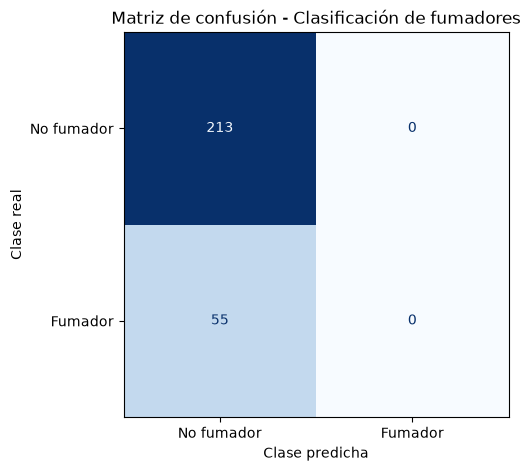

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Generar matriz de confusión
matriz = confusion_matrix(
    y_clas_test,
    predicciones_clasificacion,
    labels=["no", "yes"]
)

fig, ax = plt.subplots(figsize=(7, 5))

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No fumador", "Fumador"]
)

visualizacion.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Matriz de confusión - Clasificación de fumadores")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.show()
plt.close(fig)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Modelo con clases balanceadas
modelo_clasificacion_balanceado = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Entrenamiento
modelo_clasificacion_balanceado.fit(
    X_clas_train,
    y_clas_train
)

# Predicciones
predicciones_balanceadas = modelo_clasificacion_balanceado.predict(
    X_clas_test
)

# Métricas
print("Accuracy:",
      accuracy_score(y_clas_test, predicciones_balanceadas))

print("Precision:",
      precision_score(
          y_clas_test, predicciones_balanceadas,
          pos_label="yes", zero_division=0
      ))

print("Recall:",
      recall_score(
          y_clas_test, predicciones_balanceadas,
          pos_label="yes", zero_division=0
      ))

print("F1-score:",
      f1_score(
          y_clas_test, predicciones_balanceadas,
          pos_label="yes", zero_division=0
      ))

print("\nReporte de clasificación:")
print(classification_report(
    y_clas_test,
    predicciones_balanceadas,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(
    y_clas_test,
    predicciones_balanceadas,
    labels=["no", "yes"]
))

Accuracy: 0.6007462686567164
Precision: 0.26785714285714285
Recall: 0.5454545454545454
F1-score: 0.3592814371257485

Reporte de clasificación:
              precision    recall  f1-score   support

          no       0.84      0.62      0.71       213
         yes       0.27      0.55      0.36        55

    accuracy                           0.60       268
   macro avg       0.55      0.58      0.53       268
weighted avg       0.72      0.60      0.64       268


Matriz de confusión:
[[131  82]
 [ 25  30]]


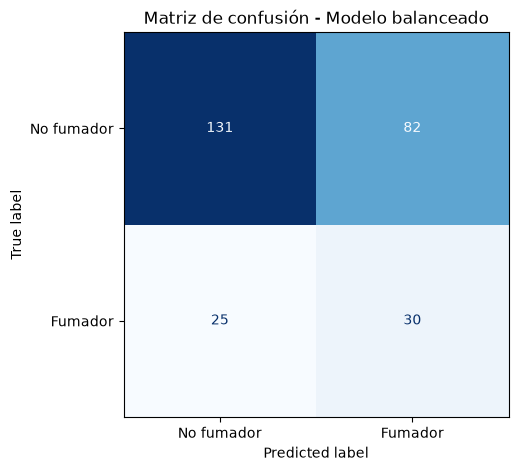

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_clas_test,
    predicciones_balanceadas,
    labels=["no", "yes"],
    display_labels=["No fumador", "Fumador"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title("Matriz de confusión - Modelo balanceado")

plt.show()
plt.close(fig)

### Interpretación del modelo de clasificación

Se implementó un modelo de regresión logística para clasificar a las personas como fumadoras o no fumadoras, utilizando edad, índice de masa corporal, número de hijos, sexo y región.

Inicialmente, el modelo obtuvo una exactitud del 79.48 %, pero clasificó a todas las personas como no fumadoras, por lo que no logró identificar ningún caso positivo.

Posteriormente, se utilizó el parámetro `class_weight="balanced"` para compensar el desequilibrio entre las clases. El nuevo modelo obtuvo una exactitud del 60.07 %, una precisión del 26.79 %, un recall del 54.55 % y un F1-score del 35.93 % para la clase fumadora.

La matriz de confusión mostró que identificó correctamente a 30 fumadores y 131 no fumadores. Sin embargo, clasificó incorrectamente a 82 no fumadores como fumadores y no identificó a 25 fumadores.

Se concluye que el balanceo permitió mejorar la identificación de la clase minoritaria, aunque aumentó los falsos positivos. Por tanto, el modelo presenta limitaciones y sus resultados deben interpretarse considerando el desequilibrio entre las clases y la información disponible en las variables predictoras.

### Entrenamiento y guardado automático del modelo de clasificación

In [ ]:
from clases_po import Clasificacion

clasificacion = Clasificacion(
    target_column="smoker",
    numeric_columns=["age", "bmi", "children"],
    categorical_columns=["sex", "region"],
    test_size=0.2,
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

resultado_clasificacion = clasificacion.ejecutar(df=df_limpio)

[clasificacion] Entrenamiento: 1069; prueba: 268
[clasificacion] Modelo guardado en: entrenamiento/20261023_031839_923395_clasificacion.pkl
[clasificacion] Métricas: {'accuracy': 0.6007462686567164, 'precision': 0.26785714285714285, 'recall': 0.5454545454545454, 'f1': 0.3592814371257485}
[clasificacion] Matriz (no, yes):
 [[131  82]
 [ 25  30]]
              precision    recall  f1-score   support

          no       0.84      0.62      0.71       213
         yes       0.27      0.55      0.36        55

    accuracy                           0.60       268
   macro avg       0.55      0.58      0.53       268
weighted avg       0.72      0.60      0.64       268



## Resumen automático de los modelos

Se genera mediante Python un archivo de texto con los resultados
de regresión y clasificación obtenidos durante la ejecución.

In [ ]:
from pathlib import Path
from datetime import datetime
import numpy as np

# ==========================================
# 1. MÉTRICAS REALES DE LOS MODELOS
# ==========================================

# Regresión lineal simple
metricas_simple = resultado_simple["metricas"]

# Regresión lineal múltiple
metricas_multiple = resultado_multiple["metricas"]

# Clasificación balanceada desde la clase Clasificacion
metricas_clasificacion = resultado_clasificacion["metricas"]

accuracy_final = metricas_clasificacion["accuracy"]
precision_final = metricas_clasificacion["precision"]
recall_final = metricas_clasificacion["recall"]
f1_final = metricas_clasificacion["f1"]

# Matriz de confusión generada por la clase
matriz_final = np.asarray(
    resultado_clasificacion["matriz_confusion"]
)

# ==========================================
# 2. DATOS DEL DATASET Y PREPROCESAMIENTO
# ==========================================

registros_originales = len(df)
registros_limpios = len(df_limpio)
duplicados_eliminados = registros_originales - registros_limpios
valores_faltantes = int(df.isna().sum().sum())

# ==========================================
# 3. FECHA DE EJECUCIÓN
# ==========================================

fecha = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# ==========================================
# 4. GENERAR RESUMEN AUTOMÁTICO
# ==========================================

resumen = f"""
ACTIVIDAD 2 - MACHINE LEARNING
RESUMEN AUTOMÁTICO DE REGRESIÓN Y CLASIFICACIÓN

Fecha de ejecución: {fecha}

==================================================
1. INFORMACIÓN DEL DATASET
==================================================

Dataset: shijiabraham/insurance-data
Enlace: https://huggingface.co/datasets/shijiabraham/insurance-data
Split utilizado: train

Registros originales: {registros_originales}
Registros después de limpieza: {registros_limpios}
Duplicados eliminados: {duplicados_eliminados}
Valores faltantes originales: {valores_faltantes}

Columnas:
age, sex, bmi, children, smoker, region, charges

PREPROCESAMIENTO APLICADO

- Identificación de valores faltantes y duplicados.
- Eliminación de registros duplicados exactos.
- Selección de variables predictoras y objetivo.
- División de los datos en entrenamiento y prueba.
- Estandarización de age, bmi y children para clasificación.
- Codificación OneHotEncoder de sex y region.
- Ajuste de las transformaciones únicamente
  con los datos de entrenamiento.

==================================================
2. REGRESIÓN LINEAL SIMPLE
==================================================

Objetivo:
Predecir los costos médicos de una persona.

Variable predictora: bmi
Variable objetivo: charges

Algoritmo: LinearRegression
Parámetros: valores predeterminados de scikit-learn

Configuración:
Entrenamiento: 80%
Prueba: 20%
random_state: 42

RESULTADOS

MAE: {metricas_simple["mae"]:.2f}
RMSE: {metricas_simple["rmse"]:.2f}
R2: {metricas_simple["r2"]:.4f}

Coeficiente BMI:
{resultado_simple["parametros"]["w"]}

Intercepto:
{resultado_simple["parametros"]["b"]}

INTERPRETACIÓN

El modelo explica aproximadamente
{metricas_simple["r2"] * 100:.2f}% de la variación
de los costos médicos en el conjunto de prueba.

El MAE indica que las predicciones presentan
un error absoluto promedio de
{metricas_simple["mae"]:.2f} unidades monetarias.

==================================================
3. REGRESIÓN LINEAL MÚLTIPLE
==================================================

Objetivo:
Predecir los costos médicos utilizando edad e IMC.

Variables predictoras: age, bmi
Variable objetivo: charges

Algoritmo: LinearRegression
Parámetros: valores predeterminados de scikit-learn

Configuración:
Entrenamiento: 80%
Prueba: 20%
random_state: 42

RESULTADOS

MAE: {metricas_multiple["mae"]:.2f}
RMSE: {metricas_multiple["rmse"]:.2f}
R2: {metricas_multiple["r2"]:.4f}

Coeficientes (age, bmi):
{resultado_multiple["parametros"]["w"]}

Intercepto:
{resultado_multiple["parametros"]["b"]}

INTERPRETACIÓN

El modelo explica aproximadamente
{metricas_multiple["r2"] * 100:.2f}% de la variación
de los costos médicos en el conjunto de prueba.

La incorporación de la edad permite evaluar
si utilizar dos variables mejora la predicción
respecto al modelo de regresión simple.

==================================================
4. MODELO DE CLASIFICACIÓN
==================================================

Objetivo:
Clasificar si una persona es fumadora o no fumadora.

Variable objetivo: smoker

Clases:
- no: No fumador
- yes: Fumador

Variables predictoras:
age, bmi, children, sex, region

Algoritmo: LogisticRegression

PARÁMETROS

max_iter: 1000
class_weight: balanced
random_state: 42
Otros parámetros: valores predeterminados

Configuración:
Entrenamiento: 80%
Prueba: 20%
Estratificación: smoker

RESULTADOS

Accuracy: {accuracy_final:.4f}
Precision (fumadores): {precision_final:.4f}
Recall (fumadores): {recall_final:.4f}
F1-score (fumadores): {f1_final:.4f}

MATRIZ DE CONFUSIÓN

Orden de las clases: no, yes
Filas: clases reales
Columnas: clases predichas

{matriz_final}

INTERPRETACIÓN

La exactitud general del clasificador fue de
{accuracy_final * 100:.2f}%.

El modelo identificó aproximadamente
{recall_final * 100:.2f}% de las personas fumadoras.

La precisión para la clase fumadora fue de
{precision_final * 100:.2f}%.

El F1-score fue de
{f1_final * 100:.2f}%.

El parámetro class_weight="balanced" permitió
dar mayor importancia a la clase minoritaria.

Sin embargo, el modelo todavía presenta
dificultades para identificar correctamente
a todas las personas fumadoras y no fumadoras.

==================================================
5. COMPARACIÓN DE REGRESIONES
==================================================

R2 regresión simple: {metricas_simple["r2"]:.4f}
R2 regresión múltiple: {metricas_multiple["r2"]:.4f}

Diferencia de R2:
{metricas_multiple["r2"] - metricas_simple["r2"]:.4f}

MAE regresión simple: {metricas_simple["mae"]:.2f}
MAE regresión múltiple: {metricas_multiple["mae"]:.2f}

==================================================
6. CONCLUSIONES Y LIMITACIONES
==================================================

La regresión lineal permite estimar costos médicos
utilizando características numéricas del dataset.

El modelo múltiple incorpora edad e IMC,
mientras que el simple utiliza únicamente IMC.

Ambos modelos tienen una capacidad predictiva
limitada debido a que los costos médicos pueden
depender de otras características no incluidas.

En clasificación, el balanceo de clases permite
mejorar la detección de fumadores frente a una
configuración que predice únicamente la clase
mayoritaria, aunque puede aumentar los falsos
positivos.

Las métricas corresponden a los datos de prueba
obtenidos durante esta ejecución.

FIN DEL REPORTE
"""

# ==========================================
# 5. GUARDAR ARCHIVO TXT AUTOMÁTICAMENTE
# ==========================================

ruta_reporte = Path("resumen_modelos_actividad2.txt")

ruta_reporte.write_text(
    resumen.strip() + "\n",
    encoding="utf-8"
)

print("Resumen generado correctamente:")
print(ruta_reporte.resolve())

# ==========================================
# 6. VERIFICAR ARCHIVO
# ==========================================

print("\nArchivo existente:", ruta_reporte.exists())
print("Tamaño del archivo:", ruta_reporte.stat().st_size, "bytes")

Resumen generado correctamente:
/workspaces/Machine_Learning/src/carga_datos/resumen_modelos_actividad2.txt

Archivo existente: True
Tamaño del archivo: 4834 bytes
